
# I — Data Audit & Validation

## Objective
Inspect the classification and detection datasets to assess data quality, identify potential issues, and verify dataset structure before preprocessing and model training.


## 1. Dataset Configuration and Overview

The following cells import the audit functions, display the dataset configuration, and locate the classification and detection dataset directories.

In [10]:
import sys
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

In [11]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [24]:
from src.data.audit_data import (
    overview,
    exploration,
    get_class_dirs,
    print_class_summary,
    print_image_issues,
    display_sample_images,
    collect_image_shapes,
    print_image_dimensions,
    plot_dimension_counts,
    plot_aspect_ratios,
)

In [14]:
overview()

Project directory: /home/houssam/Documents/brief-5
Dataset directory: /home/houssam/Documents/brief-5/Data
Dataset exists: True
Image size: (224, 224)
Supported extensions: {'.jpg', '.jpeg', '.bmp', '.png'}


In [15]:
classification, detection = exploration()

Number of Paths in Data folder: 2
classification
detection



## 2. Classification Dataset Audit


### 2.1. Explore Dataset Structure and Classes

This function returns the class directories inside the classification dataset.

In [16]:
class_dirs = get_class_dirs(classification)

### 2.2. Count Images per Class

This function prints the number of files, supported images, and training or testing prefixes for every class.

In [17]:
print_class_summary(class_dirs)

Number of classes: 4
Class: glioma
  Total files: 1621
  Supported images: 1621
  Training prefix (Tr-): 1321
  Testing prefix (Te-): 300

Class: meningioma
  Total files: 1645
  Supported images: 1645
  Training prefix (Tr-): 1339
  Testing prefix (Te-): 306

Class: notumor
  Total files: 2000
  Supported images: 2000
  Training prefix (Tr-): 1595
  Testing prefix (Te-): 405

Class: pituitary
  Total files: 1757
  Supported images: 1757
  Training prefix (Tr-): 1457
  Testing prefix (Te-): 300

Total of images : 7023
From 7023 of files


### 2.3. Validate File Extensions and Image Readability

This function counts unsupported files and detects images that OpenCV cannot read.

In [18]:
print_image_issues(class_dirs)

Total supported image files: 7023
Unreadable images: 0
Unsupported files: 0


### 2.4. Display Representative Images

This function displays up to three supported sample images from each class for a visual quality check.

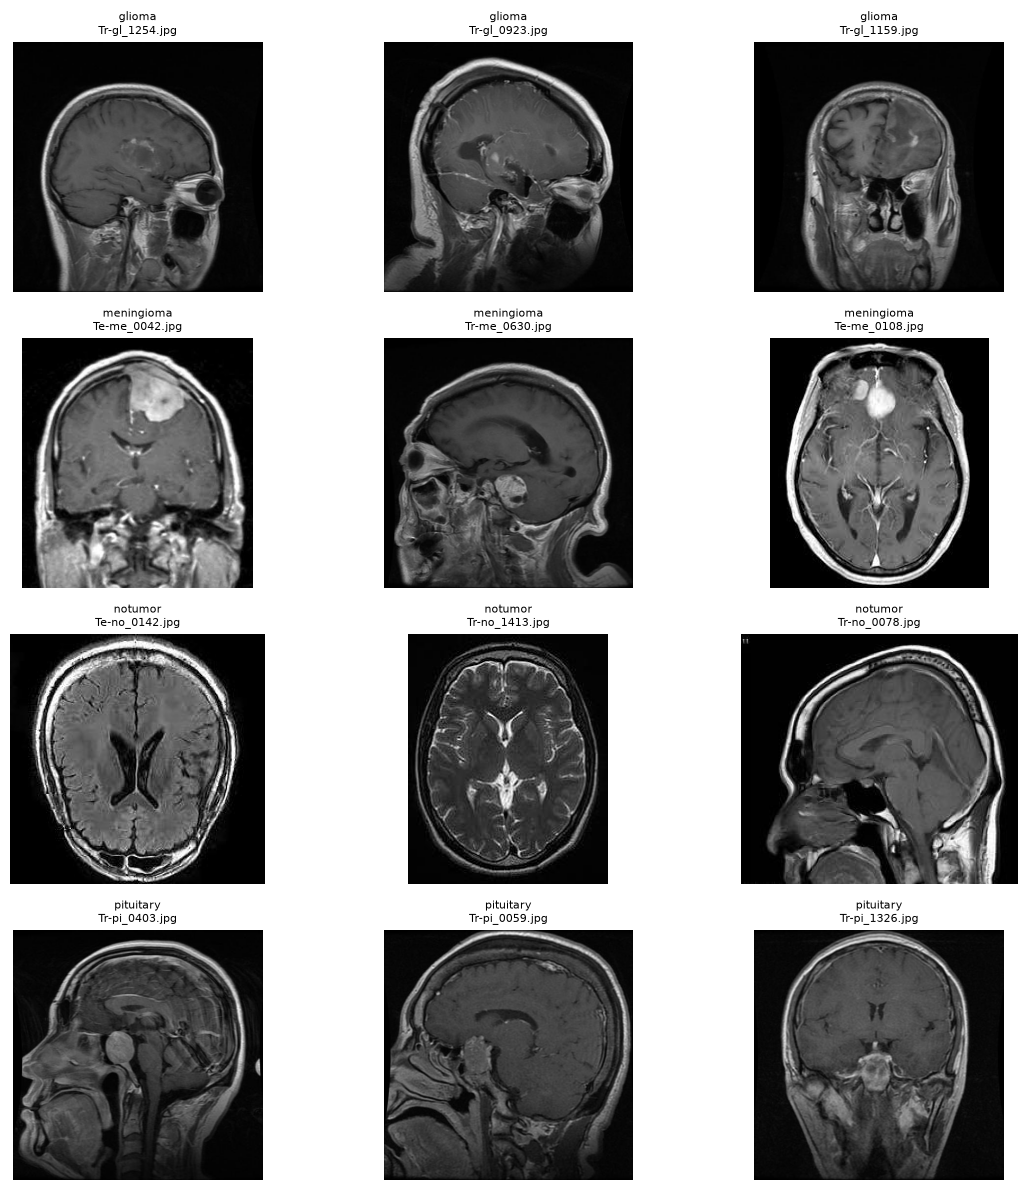

In [19]:
display_sample_images(class_dirs)

### 2.5. Analyze Image Dimensions

This function reads valid images and collects their height and width frequencies for later reporting and plotting.

In [20]:
image_shapes = collect_image_shapes(class_dirs)

### 2.6. Report Common Image Dimensions

This function prints the number of unique dimensions and the minimum, maximum, and most common image sizes.

In [21]:
print_image_dimensions(image_shapes)

Number of unique image dimensions: 387

Most common dimensions:
(512, 512): 4742 images
(225, 225): 332 images
(630, 630): 90 images
(236, 236): 81 images
(251, 201): 58 images
(221, 228): 51 images
(217, 232): 50 images
(168, 300): 49 images
(442, 442): 46 images
(198, 150): 44 images

Minimum width: 150
Maximum width: 1920
Minimum height: 168
Maximum height: 1446


### 2.7. Plot Dimension Distribution

This function plots the ten most frequent image dimensions to make size variation easier to compare.

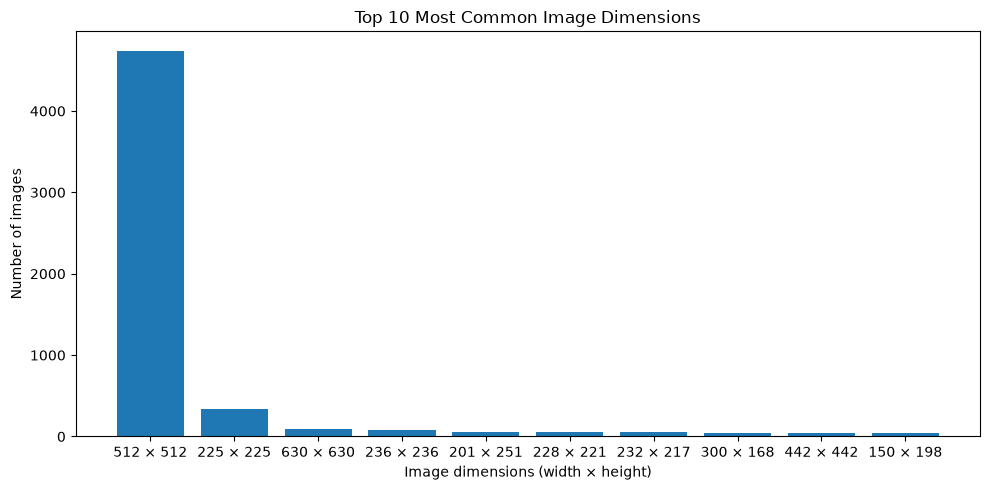

In [22]:
plot_dimension_counts(image_shapes)

### 2.8. Plot Aspect-Ratio Distribution

This function plots the distribution of image width-to-height ratios to reveal unusually wide or tall images.

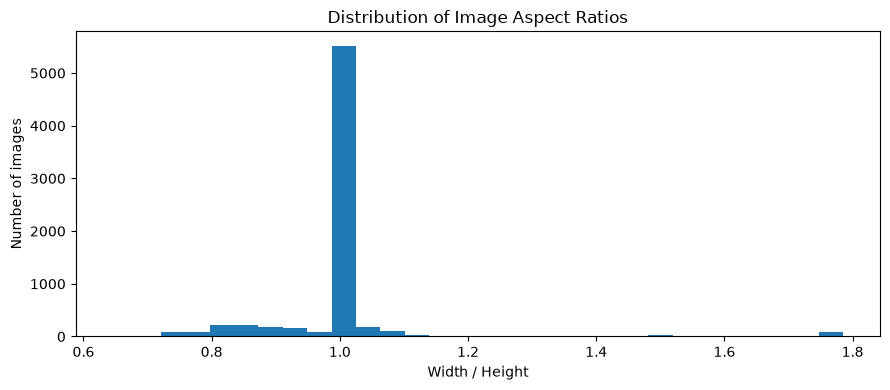

Minimum aspect ratio: 0.645
Maximum aspect ratio: 1.786


In [23]:
plot_aspect_ratios(image_shapes)